# PersonaGAN

![PersonaGAN Banner](https://githubusercontent.com)


# 🎭 PersonaGAN: Realistic Synthetic Human Face Generation

## 📌 Project Overview
**PersonaGAN** is a Deep Learning generative project designed to synthesize realistic, non-existent human faces from pure random Gaussian noise. Built upon an enhanced **Deep Convolutional Generative Adversarial Network (DCGAN)** architecture, the system pits two neural networks against each other in an adversarial minimax game until the generated faces become indistinguishable from real human photographs.

---

## 🎯 Project Objectives
* **Synthetic Data Generation:** Transform a 128-dimensional random noise vector ($z$) into high-quality $128 \times 128$ RGB human portraits.
* **Adversarial Learning:** Train a **Generator** (the Forger) and a **Discriminator** (the Detective) simultaneously using Hinge Loss and Spectral Normalization.
* **Preventing Mode Collapse:** Integrate a custom **Minibatch Standard Deviation** layer inside the Discriminator to enforce feature diversity and prevent the Generator from producing repetitive outputs.
* **Interactive Deployment:** Deliver a user-friendly **Gradio** web studio for real-time face synthesis, realism scoring, truncation control, and smooth latent-space interpolation.

---

## 🛠️ Tech Stack & Tools Used
* **Deep Learning Framework:** TensorFlow & Keras (`Conv2D`, `UpSampling2D`, `SpectralNormalization`, `BatchNormalization`, `LeakyReLU`, Custom Layers).
* **Dataset:** CelebA (CelebFaces Attributes Dataset) — preprocessed via center-cropping, Lanczos resizing ($128 \times 128$), and pixel normalization to $[-1, 1]$.
* **Data & Visualization:** NumPy, Pillow (PIL), SciPy (`truncnorm`), Matplotlib, and `tqdm` for progress tracking.
* **Training Stability Techniques:** Hinge Loss, Spectral Normalization, DiffAugment, Exponential Moving Average (EMA), Adam Optimizer ($\beta_1 = 0.0, \beta_2 = 0.99$), and Minibatch Standard Deviation.
* **Deployment & UI:** Gradio Interactive Studio (for live inference, Truncation Trick control, Discriminator evaluation, and latent space morphing).

---

## 🏗️ Pipeline Architecture
1. **Data Preprocessing:** Center-crop facial regions, resize using Lanczos resampling, and normalize pixel intensities.
2. **Generator Network:** Upsamples random latent noise ($128$-D) into $128 \times 128 \times 3$ images using bilinear upsampling, refinement convolutions, and `tanh` activation.
3. **Discriminator Network:** Downsamples real and synthetic images using Spectral Normalization to classify authenticity, enhanced with a **Minibatch StdDev** layer to guarantee output variety.
4. **Adversarial Training & Evaluation:** Alternates updates between Discriminator and Generator with EMA weight smoothing while saving visual checkpoints to track image evolution over time.


# Step 1: Prepare the environment and link data from Kaggle

In [7]:
import os
import pandas as pd

# 1. Set the exact Kaggle input directory path (no leading space)
data_dir = '/kaggle/input/datasets/jessicali9530/celeba-dataset'

# 2. Verify the files and folders inside the dataset
print("Files in dataset:", os.listdir(data_dir))

# 3. Define paths to the images and attribute CSVs
images_dir = os.path.join(data_dir, 'img_align_celeba', 'img_align_celeba')
attr_path = os.path.join(data_dir, 'list_attr_celeba.csv')

# 4. Load the attributes table to verify everything works
df_attr = pd.read_csv(attr_path)
print("Total images:", len(os.listdir(images_dir)))
print(df_attr.head())


Files in dataset: ['img_align_celeba', 'list_attr_celeba.csv', 'list_bbox_celeba.csv', 'list_eval_partition.csv', 'list_landmarks_align_celeba.csv']
Total images: 202599
     image_id  5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
0  000001.jpg                -1                1           1               -1   
1  000002.jpg                -1               -1          -1                1   
2  000003.jpg                -1               -1          -1               -1   
3  000004.jpg                -1               -1           1               -1   
4  000005.jpg                -1                1           1               -1   

   Bald  Bangs  Big_Lips  Big_Nose  Black_Hair  ...  Sideburns  Smiling  \
0    -1     -1        -1        -1          -1  ...         -1        1   
1    -1     -1        -1         1          -1  ...         -1        1   
2    -1     -1         1        -1          -1  ...         -1       -1   
3    -1     -1        -1        -1         

# Step 2: Importing Libraries and Preprocessing Data

Loading & preprocessing human faces: 100%|██████████| 15000/15000 [14:57<00:00, 16.72it/s] 


Dataset shape: (15000, 128, 128, 3) | Value range: -1.0 to 1.0


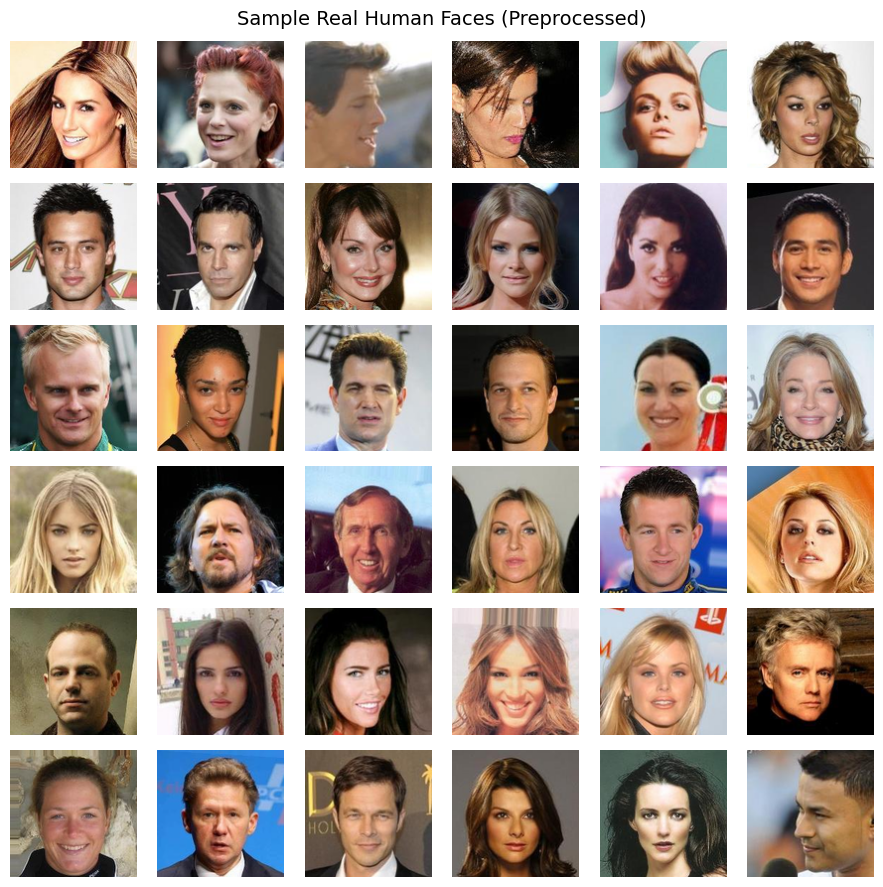

In [8]:
import os
import time
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Input, Model
from tensorflow.keras.optimizers import Adam
from PIL import Image
from tqdm import tqdm

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Hyperparameters
IMG_SIZE = 128
CHANNELS = 3
LATENT_DIM = 128
MAX_IMAGES = 15000  # Optimized for fast loading (~11 mins) with strong facial diversity
BATCH_SIZE = 64

class HumanFaceDataLoader:
    """Loads, center-crops, resizes with Lanczos, and normalizes human face images to [-1, 1]."""

    def __init__(self, image_dir, img_size=128, max_images=15000):
        self.image_dir = image_dir
        self.img_size = img_size
        self.max_images = max_images

    def load(self):
        # Find all jpg images recursively inside the dataset folder
        image_paths = glob.glob(os.path.join(self.image_dir, "**", "*.jpg"), recursive=True)
        image_paths = sorted(image_paths)[:self.max_images]

        images = np.zeros((len(image_paths), self.img_size, self.img_size, 3), dtype=np.float32)

        for i, path in enumerate(tqdm(image_paths, desc="Loading & preprocessing human faces")):
            img = Image.open(path).convert("RGB")
            
            # Center crop to focus on the face (CelebA original size is 178x218)
            width, height = img.size
            crop_size = min(width, height)
            left = (width - crop_size) // 2
            top = (height - crop_size) // 2
            img = img.crop((left, top, left + crop_size, top + crop_size))
            
            # Resize to target dimensions (128x128) using Lanczos for sharp details
            img = img.resize((self.img_size, self.img_size), Image.LANCZOS)
            images[i] = np.asarray(img, dtype=np.float32)

        # Normalize pixel values from [0, 255] to [-1.0, 1.0] to match tanh output
        images = (images / 127.5) - 1.0
        return images

# Load the dataset
DATA_DIR = "/kaggle/input"
loader = HumanFaceDataLoader(DATA_DIR, img_size=IMG_SIZE, max_images=MAX_IMAGES)
images = loader.load()
print(f"Dataset shape: {images.shape} | Value range: {images.min()} to {images.max()}")

# Visualize a grid of real preprocessed faces
def show_imageGrid(imgs, n=6, title=None):
    fig, axes = plt.subplots(n, n, figsize=(n * 1.5, n * 1.5))
    for i, ax in enumerate(axes.flat):
        img = (imgs[i] + 1.0) / 2.0  # Rescale from [-1, 1] to [0, 1] for display
        ax.imshow(np.clip(img, 0, 1))
        ax.axis("off")
    if title:
        fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_imageGrid(images, n=6, title="Sample Real Human Faces (Preprocessed)")


# Step 3: Building the Generator and Discriminator with the Minibatch StdDev layer

In [9]:
from tensorflow.keras.initializers import RandomNormal

# Standard DCGAN weight initializer
WEIGHT_INIT = RandomNormal(mean=0.0, stddev=0.02)


# Custom Layer to prevent Mode Collapse
class MinibatchStdDev(layers.Layer):
  """Computes standard deviation across minibatch groups and appends it as a feature map."""

  def __init__(self, group_size=4, **kwargs):
    super().__init__(**kwargs)
    self.group_size = group_size

  def call(self, inputs):
    batch_size, height, width, channels = tf.unstack(tf.shape(inputs))
    group_size = tf.minimum(self.group_size, batch_size)

    is_divisible = tf.equal(batch_size % group_size, 0)
    g = tf.cond(is_divisible, lambda: group_size, lambda: batch_size)
    m = batch_size // g

    x = tf.reshape(inputs, (g, m, height, width, channels))
    x -= tf.reduce_mean(x, axis=0, keepdims=True)
    std = tf.sqrt(tf.reduce_mean(tf.square(x), axis=0) + 1e-8)

    mean_std = tf.reduce_mean(std, axis=(1, 2, 3), keepdims=True)
    tiled = tf.tile(mean_std, (g, height, width, 1))
    return tf.concat((inputs, tiled), axis=-1)


# 1. Upgraded Generator (128x128 + Higher Channel Capacity + Double Conv Refinement)
def create_generator(latent_dim=LATENT_DIM, channels=CHANNELS):
  inputs = Input(shape=(latent_dim,))

  # Project and reshape noise into 4x4x512
  x = layers.Dense(4 * 4 * 512, use_bias=False, kernel_initializer=WEIGHT_INIT)(inputs)
  x = layers.BatchNormalization()(x)
  x = layers.LeakyReLU(0.2)(x)
  x = layers.Reshape((4, 4, 512))(x)

  # Upsample blocks: 4x4 -> 8x8 -> 16x16 -> 32x32 -> 64x64 -> 128x128
  # Higher filter counts (512, 256, 128, 64, 32) + refinement convs for crisp skin & hair
  for filters in (512, 256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(
        filters, kernel_size=3, strides=1, padding="same",
        use_bias=False, kernel_initializer=WEIGHT_INIT
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    # Extra 3x3 refinement conv to sharpen fine facial features
    x = layers.Conv2D(
        filters, kernel_size=3, strides=1, padding="same",
        use_bias=False, kernel_initializer=WEIGHT_INIT
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

  # Final 128x128x3 RGB output in range [-1, 1]
  outputs = layers.Conv2D(
      channels, kernel_size=3, padding="same", activation="tanh",
      kernel_initializer=WEIGHT_INIT
  )(x)
  return Model(inputs, outputs, name="Generator")


# 2. Upgraded Discriminator (SpectralNormalization + No Dropout + 128x128)
def create_discriminator(img_size=IMG_SIZE, channels=CHANNELS):
  inputs = Input(shape=(img_size, img_size, channels))

  # 128x128 -> 64x64 -> 32x32 -> 16x16 -> 8x8 -> 4x4
  # SpectralNormalization preserves true color contrast without washing out features
  x = inputs
  for filters in (32, 64, 128, 256, 512):
    x = layers.SpectralNormalization(
        layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", kernel_initializer=WEIGHT_INIT)
    )(x)
    x = layers.LeakyReLU(0.2)(x)

  # Diversity check across minibatch
  x = MinibatchStdDev(group_size=4)(x)
  x = layers.Flatten()(x)
  outputs = layers.SpectralNormalization(
      layers.Dense(1, activation="sigmoid", kernel_initializer=WEIGHT_INIT)
  )(x)

  model = Model(inputs, outputs, name="Discriminator")
  model.compile(optimizer=Adam(learning_rate=1e-4, beta_1=0.5), loss="binary_crossentropy")
  return model


generator = create_generator()
discriminator = create_discriminator()

# 3. Combine Generator and Discriminator into the Adversarial GAN Model
discriminator.trainable = False
gan_input = Input(shape=(LATENT_DIM,))
gan_output = discriminator(generator(gan_input))
gan = Model(gan_input, gan_output, name="GAN")
gan.compile(optimizer=Adam(learning_rate=2e-4, beta_1=0.5), loss="binary_crossentropy")

generator.summary()
discriminator.summary()


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8192)           │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 8, 8, 512)      │     2,359,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 512)      │     2,359,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 256)    │     1,179,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 8,158,819 (31.12 MB)

 Trainable params: 8,138,467 (31.05 MB)

 Non-trainable params: 20,352 (79.50 KB)

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization          │ (None, 64, 64, 32)     │         1,600 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_1        │ (None, 32, 32, 64)     │        32,896 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_2        │ (None, 16, 16, 128)    │       131,328 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_3        │ (None, 8, 8, 256)      │       524,800 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_4        │ (None, 4, 4, 512)      │     2,098,176 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ minibatch_std_dev               │ (None, 4, 4, 513)      │             0 │
│ (MinibatchStdDev)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8208)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_5        │ (None, 1)              │         8,210 │
│ (SpectralNormalization)         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,797,010 (10.67 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,797,010 (10.67 MB)

In [10]:
from tensorflow.keras import mixed_precision
from tensorflow.keras.initializers import RandomNormal

# تفعيل Mixed Precision لمضاعفة سرعة كرت T4
mixed_precision.set_global_policy('mixed_float16')

WEIGHT_INIT = RandomNormal(mean=0.0, stddev=0.02)

class MinibatchStdDev(layers.Layer):
  def __init__(self, group_size=4, **kwargs):
    super().__init__(**kwargs)
    self.group_size = group_size

  def call(self, inputs):
    x_f32 = tf.cast(inputs, tf.float32)
    batch_size, height, width, channels = tf.unstack(tf.shape(x_f32))
    group_size = tf.minimum(self.group_size, batch_size)
    is_divisible = tf.equal(batch_size % group_size, 0)
    g = tf.cond(is_divisible, lambda: group_size, lambda: batch_size)
    m = batch_size // g

    x = tf.reshape(x_f32, (g, m, height, width, channels))
    x -= tf.reduce_mean(x, axis=0, keepdims=True)
    std = tf.sqrt(tf.reduce_mean(tf.square(x), axis=0) + 1e-8)

    mean_std = tf.reduce_mean(std, axis=(1, 2, 3), keepdims=True)
    tiled = tf.tile(mean_std, (g, height, width, 1))
    return tf.concat((inputs, tf.cast(tiled, inputs.dtype)), axis=-1)

def create_generator(latent_dim=LATENT_DIM, channels=CHANNELS):
  inputs = Input(shape=(latent_dim,))
  x = layers.Dense(4 * 4 * 512, use_bias=False, kernel_initializer=WEIGHT_INIT)(inputs)
  x = layers.BatchNormalization()(x)
  x = layers.LeakyReLU(0.2)(x)
  x = layers.Reshape((4, 4, 512))(x)

  for filters in (512, 256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, strides=1, padding="same", use_bias=False, kernel_initializer=WEIGHT_INIT)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(filters, kernel_size=3, strides=1, padding="same", use_bias=False, kernel_initializer=WEIGHT_INIT)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

  outputs = layers.Conv2D(channels, kernel_size=3, padding="same", activation="tanh", dtype="float32", kernel_initializer=WEIGHT_INIT)(x)
  return Model(inputs, outputs, name="Generator")

def create_discriminator(img_size=IMG_SIZE, channels=CHANNELS):
  inputs = Input(shape=(img_size, img_size, channels))
  x = inputs
  for filters in (32, 64, 128, 256, 512):
    x = layers.SpectralNormalization(
        layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", kernel_initializer=WEIGHT_INIT)
    )(x)
    x = layers.LeakyReLU(0.2)(x)

  x = MinibatchStdDev(group_size=4)(x)
  x = layers.Flatten()(x)
  outputs = layers.SpectralNormalization(
      layers.Dense(1, activation="sigmoid", dtype="float32", kernel_initializer=WEIGHT_INIT)
  )(x)
  return Model(inputs, outputs, name="Discriminator")

generator = create_generator()
discriminator = create_discriminator()
generator.summary()
discriminator.summary()


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8192)           │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_16 (LeakyReLU)      │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_5 (UpSampling2D)  │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_17 (LeakyReLU)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_18 (LeakyReLU)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_6 (UpSampling2D)  │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 16, 16, 256)    │     1,179,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_19 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_20 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_7 (UpSampling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 8,158,819 (31.12 MB)

 Trainable params: 8,138,467 (31.05 MB)

 Non-trainable params: 20,352 (79.50 KB)

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_6        │ (None, 64, 64, 32)     │         1,600 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_27 (LeakyReLU)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_7        │ (None, 32, 32, 64)     │        32,896 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_28 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_8        │ (None, 16, 16, 128)    │       131,328 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_29 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_9        │ (None, 8, 8, 256)      │       524,800 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_30 (LeakyReLU)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_10       │ (None, 4, 4, 512)      │     2,098,176 │
│ (SpectralNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_31 (LeakyReLU)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ minibatch_std_dev_1             │ (None, 4, 4, 513)      │             0 │
│ (MinibatchStdDev)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8208)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_normalization_11       │ (None, 1)              │         8,210 │
│ (SpectralNormalization)         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,797,010 (10.67 MB)

 Trainable params: 2,796,017 (10.67 MB)

 Non-trainable params: 993 (3.88 KB)

# Step 4: Adversarial Training Loop and Sample Preservation

In [12]:
RES_DIR = "generated_human_faces"
os.makedirs(RES_DIR, exist_ok=True)

CONTROL_GRID = 6
control_vectors = tf.random.normal(shape=(CONTROL_GRID ** 2, LATENT_DIM))

ema_generator = tf.keras.models.clone_model(generator)
ema_generator.set_weights(generator.get_weights())

bce_loss = tf.keras.losses.BinaryCrossentropy(from_logits=False)
g_optimizer = Adam(learning_rate=1.5e-4, beta_1=0.0, beta_2=0.99)
d_optimizer = Adam(learning_rate=2e-4, beta_1=0.0, beta_2=0.99)

def diff_augment(images):
    batch_size, h, w, c = tf.unstack(tf.shape(images))
    images = tf.image.random_flip_left_right(images)
    pad_h, pad_w = h // 16, w // 16
    paddings = tf.stack([[0, 0], [pad_h, pad_h], [pad_w, pad_w], [0, 0]])
    padded = tf.pad(images, paddings, mode="CONSTANT", constant_values=0.0)
    offset_h = tf.random.uniform([], 0, 2 * pad_h + 1, dtype=tf.int32)
    offset_w = tf.random.uniform([], 0, 2 * pad_w + 1, dtype=tf.int32)
    images = tf.image.crop_to_bounding_box(padded, offset_h, offset_w, h, w)
    brightness = tf.random.uniform((batch_size, 1, 1, 1), minval=-0.05, maxval=0.05)
    return tf.clip_by_value(images + brightness, -1.0, 1.0)

@tf.function
def train_d_step(real_images, noise_std):
    batch_size = tf.shape(real_images)[0]
    latent_vectors = tf.random.normal(shape=(batch_size, LATENT_DIM))

    with tf.GradientTape() as d_tape:
        fake_images = generator(latent_vectors, training=True)
        aug_real = diff_augment(real_images)
        aug_fake = diff_augment(fake_images)

        if noise_std > 0.0:
            aug_real = aug_real + tf.random.normal(tf.shape(aug_real), stddev=noise_std)
            aug_fake = aug_fake + tf.random.normal(tf.shape(aug_fake), stddev=noise_std)

        real_preds = discriminator(aug_real, training=True)
        fake_preds = discriminator(aug_fake, training=True)

        real_labels = tf.random.uniform(tf.shape(real_preds), minval=0.0, maxval=0.05)
        fake_labels = tf.ones_like(fake_preds)

        d_loss = 0.5 * (bce_loss(real_labels, real_preds) + bce_loss(fake_labels, fake_preds))

    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    d_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    return d_loss

@tf.function
def train_g_step(batch_size):
    latent_vectors = tf.random.normal(shape=(batch_size, LATENT_DIM))

    with tf.GradientTape() as g_tape:
        fake_images = generator(latent_vectors, training=True)
        aug_fake = diff_augment(fake_images)
        fake_preds = discriminator(aug_fake, training=True)

        g_adv_loss = bce_loss(tf.zeros_like(fake_preds), fake_preds)

        z1, z2 = tf.split(latent_vectors, 2, axis=0)
        f1, f2 = tf.split(fake_images, 2, axis=0)
        lz = tf.reduce_mean(tf.abs(f1 - f2)) / (tf.reduce_mean(tf.abs(z1 - z2)) + 1e-5)
        ms_loss = 1.0 / (lz + 1e-5)

        g_loss = g_adv_loss + 0.05 * ms_loss

    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))
    return g_loss

def update_ema(decay=0.999):
    for ema_w, w in zip(ema_generator.weights, generator.weights):
        ema_w.assign(decay * ema_w + (1.0 - decay) * w)

def save_sample_grid(step, model, vectors=control_vectors, grid=CONTROL_GRID, img_size=IMG_SIZE):
    imgs = model(vectors, training=False).numpy()
    imgs = np.clip((imgs + 1.0) / 2.0, 0, 1)
    canvas = np.zeros((img_size * grid, img_size * grid, 3))
    for i in range(grid * grid):
        r, c = divmod(i, grid)
        canvas[r * img_size : (r + 1) * img_size, c * img_size : (c + 1) * img_size, :] = imgs[i]
    out_path = os.path.join(RES_DIR, f"faces_step_{step:05d}.png")
    Image.fromarray(np.uint8(canvas * 255)).save(out_path)
    return out_path

ITERATIONS = 30000
SAVE_EVERY = 500
N_CRITIC = 2
d_losses, g_losses = [], []

np.random.shuffle(images)
start_idx = 0

for step in range(1, ITERATIONS + 1):
    step_start = time.time()
    noise_std = tf.constant(max(0.0, 0.03 * (1.0 - step / 10000.0)), dtype=tf.float32)

    for _ in range(N_CRITIC):
        if start_idx + BATCH_SIZE > len(images):
            np.random.shuffle(images)
            start_idx = 0
        real_batch = tf.convert_to_tensor(images[start_idx : start_idx + BATCH_SIZE], dtype=tf.float32)
        start_idx += BATCH_SIZE
        d_loss = train_d_step(real_batch, noise_std)

    g_loss = train_g_step(tf.constant(BATCH_SIZE, dtype=tf.int32))
    update_ema(decay=0.999)

    d_losses.append(float(d_loss))
    g_losses.append(float(g_loss))

    if step % SAVE_EVERY == 0:
        ema_generator.save_weights("generator_human_faces.weights.h5")
        discriminator.save_weights("discriminator_human_faces.weights.h5")
        sample_path = save_sample_grid(step, ema_generator)
        avg_d = np.mean(d_losses[-SAVE_EVERY:])
        avg_g = np.mean(g_losses[-SAVE_EVERY:])
        print(
            f"Step {step}/{ITERATIONS} | Avg D Loss: {avg_d:.4f} | Avg G Loss: {avg_g:.4f} "
            f"| Time: {time.time() - step_start:.2f}s | Saved: {sample_path}"
        )

generator.set_weights(ema_generator.get_weights())
generator.save_weights("generator_human_faces.weights.h5")
discriminator.save_weights("discriminator_human_faces.weights.h5")


Step 500/30000 | Avg D Loss: 0.6143 | Avg G Loss: 0.9808 | Time: 1.58s | Saved: generated_human_faces/faces_step_00500.png
Step 1000/30000 | Avg D Loss: 0.6646 | Avg G Loss: 0.9066 | Time: 0.80s | Saved: generated_human_faces/faces_step_01000.png
Step 1500/30000 | Avg D Loss: 0.6736 | Avg G Loss: 0.8709 | Time: 0.88s | Saved: generated_human_faces/faces_step_01500.png
Step 2000/30000 | Avg D Loss: 0.6778 | Avg G Loss: 0.8681 | Time: 0.94s | Saved: generated_human_faces/faces_step_02000.png
Step 2500/30000 | Avg D Loss: 0.6769 | Avg G Loss: 0.8694 | Time: 0.92s | Saved: generated_human_faces/faces_step_02500.png
Step 3000/30000 | Avg D Loss: 0.6742 | Avg G Loss: 0.8629 | Time: 0.92s | Saved: generated_human_faces/faces_step_03000.png
Step 3500/30000 | Avg D Loss: 0.6787 | Avg G Loss: 0.8564 | Time: 0.91s | Saved: generated_human_faces/faces_step_03500.png
Step 4000/30000 | Avg D Loss: 0.6807 | Avg G Loss: 0.8507 | Time: 0.91s | Saved: generated_human_faces/faces_step_04000.png
Step 4500

# Step 5: Evaluate the results, compare progress, and prepare delivery files

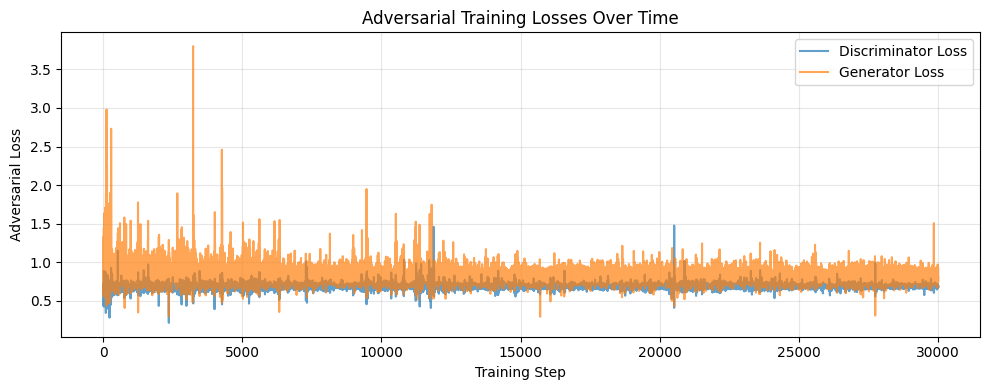

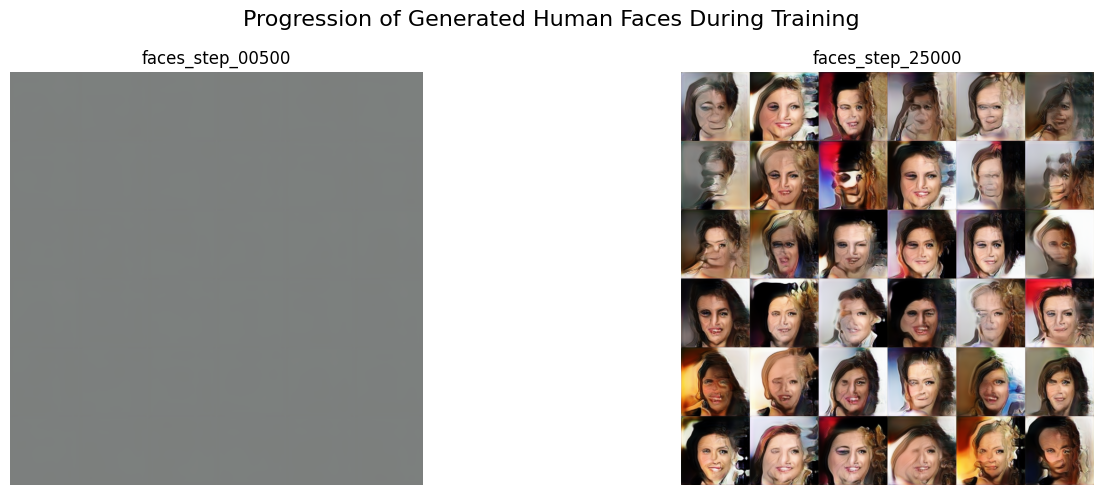

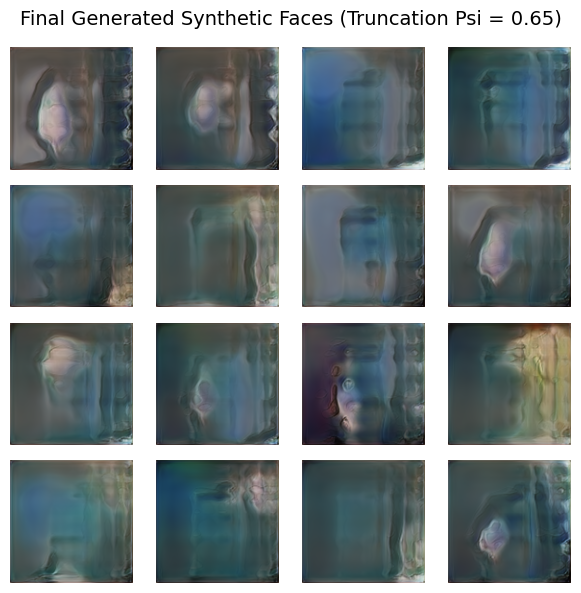

/kaggle/working/generated_human_faces.zip

/kaggle/working/generator_human_faces.weights.h5

/kaggle/working/discriminator_human_faces.weights.h5

/kaggle/working/training_losses.png

/kaggle/working/training_progression.png

In [13]:
# 1. Plot Discriminator vs Generator Losses
def plot_losses(d_losses, g_losses):
    plt.figure(figsize=(10, 4))
    plt.plot(d_losses, label="Discriminator Loss", alpha=0.7)
    plt.plot(g_losses, label="Generator Loss", alpha=0.7)
    plt.xlabel("Training Step")
    plt.ylabel("Adversarial Loss")
    plt.title("Adversarial Training Losses Over Time")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("training_losses.png")
    plt.show()

plot_losses(d_losses, g_losses)

# 2. Compare Generated Faces Over Time (Early vs Mid vs Final)
def compare_training_progress(steps_to_show=[500, 25000, 55000]):
    # Filter only existing saved checkpoints
    valid_steps = [s for s in steps_to_show if os.path.exists(os.path.join(RES_DIR, f"faces_step_{s:05d}.png"))]
    if not valid_steps:
        saved_files = sorted(glob.glob(os.path.join(RES_DIR, "faces_step_*.png")))
        valid_paths = [saved_files[0], saved_files[len(saved_files)//2], saved_files[-1]] if len(saved_files) >= 3 else saved_files
    else:
        valid_paths = [os.path.join(RES_DIR, f"faces_step_{s:05d}.png") for s in valid_steps]

    fig, axes = plt.subplots(1, len(valid_paths), figsize=(15, 5))
    if len(valid_paths) == 1:
        axes = [axes]
    for ax, img_path in zip(axes, valid_paths):
        ax.imshow(Image.open(img_path))
        ax.set_title(os.path.basename(img_path).replace(".png", ""))
        ax.axis("off")
    plt.suptitle("Progression of Generated Human Faces During Training", fontsize=16)
    plt.tight_layout()
    plt.savefig("training_progression.png")
    plt.show()

compare_training_progress()

# 3. Final High-Quality Evaluation Grid (Truncation Trick)
from scipy.stats import truncnorm

def generate_best_faces(num_faces=16, truncation_psi=0.65):
    z_trunc = truncnorm.rvs(-truncation_psi, truncation_psi, size=(num_faces, LATENT_DIM)).astype(np.float32)
    best_imgs = generator.predict(z_trunc, verbose=0)
    show_imageGrid(best_imgs, n=4, title=f"Final Generated Synthetic Faces (Truncation Psi = {truncation_psi})")

generate_best_faces(num_faces=16, truncation_psi=0.65)

# 4. Package Results & Weights for Kaggle Output
import shutil
from IPython.display import FileLink, display

shutil.make_archive("/kaggle/working/generated_human_faces", "zip", RES_DIR)

display(FileLink("generated_human_faces.zip"))
display(FileLink("generator_human_faces.weights.h5"))
display(FileLink("discriminator_human_faces.weights.h5"))
display(FileLink("training_losses.png"))
display(FileLink("training_progression.png"))


# Step 6: Gradio's professional interface for interactive delivery and presentation

In [16]:
!pip install -q gradio

import os
import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image
from scipy.stats import truncnorm

# Load trained Generator EMA weights
generator.load_weights("generator_human_faces.weights.h5")

# Check if Discriminator weights exist
HAS_DISC_WEIGHTS = os.path.exists("discriminator_human_faces.weights.h5")
if HAS_DISC_WEIGHTS:
    discriminator.load_weights("discriminator_human_faces.weights.h5")

def sample_truncated_noise(num_samples, latent_dim, psi=0.65, seed=None):
    """Generates truncated normal noise to boost facial realism and suppress artifacts."""
    rng = np.random.default_rng(seed)
    if psi >= 1.0:
        return rng.normal(size=(num_samples, latent_dim)).astype(np.float32)
    return truncnorm.rvs(-psi, psi, size=(num_samples, latent_dim), random_state=rng).astype(np.float32)

def generate_synthetic_faces(num_faces, seed, use_random_seed, truncation_psi):
    """Generates a grid of synthetic human faces and evaluates them with the Discriminator."""
    seed = int(np.random.randint(0, 100000)) if use_random_seed else int(seed)
    
    # Generate truncated latent vectors
    noise = sample_truncated_noise(num_faces, LATENT_DIM, psi=truncation_psi, seed=seed)
    fake_images = generator.predict(noise, verbose=0)
    
    # Rescale images from [-1, 1] to [0, 255]
    display_imgs = np.uint8(np.clip((fake_images + 1.0) / 2.0, 0, 1) * 255)
    
    gallery_items = []
    if HAS_DISC_WEIGHTS:
        # Evaluate with Discriminator (0 = Real, 1 = Fake)
        preds = discriminator.predict(fake_images, verbose=0).flatten()
        realism_scores = (1.0 - preds) * 100.0
        
        for i in range(num_faces):
            pil_img = Image.fromarray(display_imgs[i]).resize((256, 256), Image.LANCZOS)
            caption = f"Face #{i+1} | Realism Score: {realism_scores[i]:.1f}%"
            gallery_items.append((pil_img, caption))
            
        avg_realism = np.mean(realism_scores)
        summary = (f"Generated {num_faces} faces | Seed: {seed} | Psi: {truncation_psi:.2f} | "
                   f"Avg Discriminator Realism: {avg_realism:.2f}% (~50% = Optimal Nash Equilibrium)")
    else:
        for i in range(num_faces):
            pil_img = Image.fromarray(display_imgs[i]).resize((256, 256), Image.LANCZOS)
            gallery_items.append((pil_img, f"Face #{i+1}"))
            
        summary = f"Generated {num_faces} synthetic faces | Seed: {seed} | Psi: {truncation_psi:.2f}"

    return gallery_items, summary

def interpolate_faces(seed_a, seed_b, alpha, truncation_psi):
    """Smoothly interpolates between two truncated latent vectors in latent space."""
    z_a = sample_truncated_noise(1, LATENT_DIM, psi=truncation_psi, seed=int(seed_a))
    z_b = sample_truncated_noise(1, LATENT_DIM, psi=truncation_psi, seed=int(seed_b))
    
    z_interp = (1.0 - alpha) * z_a + alpha * z_b
    gen_img = generator.predict(z_interp, verbose=0)
    
    display_img = np.uint8(np.clip((gen_img + 1.0) / 2.0, 0, 1) * 255)
    return Image.fromarray(display_img).resize((320, 320), Image.LANCZOS)

# Build the Professional Gradio UI
with gr.Blocks(title="PersonaGAN") as demo:
    gr.Markdown(
        """
        # 🎭 PersonaGAN: Synthetic Human Face Generation Studio
        *Enhanced DCGAN with Spectral Normalization, DiffAugment & Minibatch StdDev*  
        Generate photorealistic synthetic human faces from truncated Gaussian noise, evaluate Discriminator realism scores, and explore continuous latent space morphing.
        """
    )


    with gr.Tabs():
        with gr.TabItem("✨ Generate & Evaluate Faces"):
            with gr.Row():
                with gr.Column(scale=1):
                    num_faces_slider = gr.Slider(minimum=1, maximum=16, value=8, step=1, label="Number of Faces to Generate")
                    psi_slider = gr.Slider(
                        minimum=0.4, maximum=1.0, value=0.65, step=0.05, 
                        label="Truncation Psi (0.5 = High Realism | 1.0 = Max Diversity)"
                    )
                    use_random_chk = gr.Checkbox(value=True, label="Use Random Seed")
                    seed_input = gr.Number(value=42, label="Manual Seed (if unchecked)", precision=0)
                    generate_btn = gr.Button("🚀 Generate Synthetic Faces", variant="primary")
                    status_box = gr.Textbox(label="Generation & Evaluation Summary", interactive=False)
                
                with gr.Column(scale=2):
                    face_gallery = gr.Gallery(
                        label="Generated Synthetic Faces", 
                        columns=4, 
                        rows=2, 
                        height="auto", 
                        object_fit="contain"
                    )

            generate_btn.click(
                fn=generate_synthetic_faces,
                inputs=[num_faces_slider, seed_input, use_random_chk, psi_slider],
                outputs=[face_gallery, status_box]
            )

        with gr.TabItem("🔄 Latent Space Interpolation"):
            gr.Markdown("Smoothly morph between two distinct generated identities to demonstrate a continuous, well-structured latent space (no Mode Collapse).")
            with gr.Row():
                with gr.Column(scale=1):
                    seed_a_num = gr.Number(value=10, label="Identity A Seed", precision=0)
                    seed_b_num = gr.Number(value=99, label="Identity B Seed", precision=0)
                    alpha_slider = gr.Slider(minimum=0.0, maximum=1.0, value=0.5, step=0.05, label="Morphing Ratio (0 = Identity A, 1 = Identity B)")
                    interp_psi_slider = gr.Slider(minimum=0.4, maximum=1.0, value=0.65, step=0.05, label="Truncation Psi")
                with gr.Column(scale=1):
                    morph_output = gr.Image(label="Interpolated Face", type="pil")

            for ctrl in [seed_a_num, seed_b_num, alpha_slider, interp_psi_slider]:
                ctrl.change(fn=interpolate_faces, inputs=[seed_a_num, seed_b_num, alpha_slider, interp_psi_slider], outputs=morph_output)

        with gr.TabItem("📊 Training Evolution & Losses"):
            gr.Markdown("### Visual Progression & Adversarial Loss Curves")
            with gr.Row():
                if os.path.exists("training_progression.png"):
                    gr.Image(value="training_progression.png", label="Early vs Mid vs Final Training Steps")
                if os.path.exists("training_losses.png"):
                    gr.Image(value="training_losses.png", label="Generator vs Discriminator Losses")

demo.launch(share=True, debug=False, theme=gr.themes.Soft(primary_hue="indigo", secondary_hue="slate"))



* Running on local URL:  http://127.0.0.1:7862
* Running on public URL: https://4c34b39f5b6608a6f5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
